In [2]:
import pandas as pd, numpy as np

df = pd.read_excel("../data/raw/Online Retail.xlsx")
raw_rows = len(df)

print(df.shape)
df.info()
print(df.describe())
print(df.isna().sum())
print("Duplicates:", df.duplicated().sum())
print((df["Quantity"] <= 0).sum(), (df["UnitPrice"] <= 0).sum())

(541909, 8)
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB
            Quantity                 InvoiceDate      UnitPrice     CustomerID
count  541909.000000                      541909  541909.000000  406829.000000
mean        9.552250  2011-07-04 13:34:57.156386       4.611114   15287.690570
min    -80995.000000         2010-12-01 08:26:00  -11062.06000

In [3]:
before = {
    "rows": len(df),
    "missing_total": int(df.isna().sum().sum()),
    "missing_CustomerID": int(df["CustomerID"].isna().sum()),
    "missing_Description": int(df["Description"].isna().sum()),
    "duplicates": int(df.duplicated().sum()),
    "neg_or_zero_qty": int((df["Quantity"] <= 0).sum()),
    "neg_or_zero_price": int((df["UnitPrice"] <= 0).sum()),
}
print(before)

{'rows': 541909, 'missing_total': 136534, 'missing_CustomerID': 135080, 'missing_Description': 1454, 'duplicates': 5268, 'neg_or_zero_qty': 10624, 'neg_or_zero_price': 2517}


In [4]:
df = df.drop_duplicates()

In [5]:
df = df.dropna(subset=["Description"])           # can't interpret a product with no name
df["CustomerID"] = df["CustomerID"].astype("Int64").astype(str).replace("<NA>", "Unknown")

In [6]:
df["Description"] = df["Description"].str.strip().str.upper()
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]   # removes cancellations (invoice starting with "C") and bad prices

In [7]:
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
df["StockCode"] = df["StockCode"].astype(str)
df["Country"] = df["Country"].astype("category")
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]
df["Month"] = df["InvoiceDate"].dt.month
df["Hour"] = df["InvoiceDate"].dt.hour

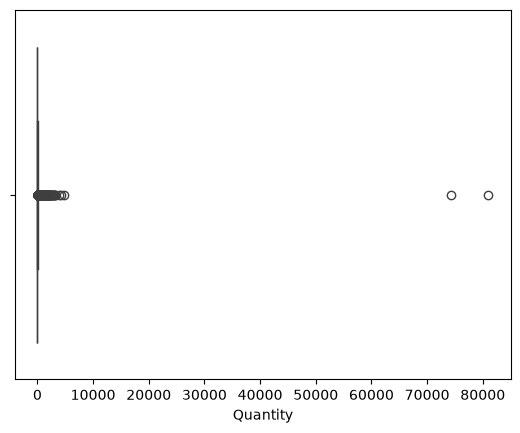

Quantity outliers: 27111
UnitPrice outliers: 37827


In [22]:
import seaborn as sns, matplotlib.pyplot as plt
sns.boxplot(x=df["Quantity"]); plt.show()

for col in ["Quantity", "UnitPrice"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5*iqr, q3 + 1.5*iqr
    print(col, "outliers:", ((df[col] < low) | (df[col] > high)).sum())
    df[col + "_capped"] = df[col].clip(low, high)   # keep original, add capped version

In [13]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
df[["Quantity_norm", "UnitPrice_norm"]] = MinMaxScaler().fit_transform(df[["Quantity_capped", "UnitPrice_capped"]])
df[["Quantity_std", "UnitPrice_std"]] = StandardScaler().fit_transform(df[["Quantity_capped", "UnitPrice_capped"]])

In [17]:
print("Rows before:", raw_rows, "after:", len(df))
print(df.isna().sum().sum(), "missing values left")
df.to_csv("../data/cleaned/online_retail_cleaned.csv", index=False)

Rows before: 541909 after: 524878
132186 missing values left


In [19]:
after = {
    "rows": len(df),
    "missing_total": int(df.isna().sum().sum()),
    "duplicates": int(df.duplicated().sum()),
    "neg_or_zero_qty": int((df["Quantity"] <= 0).sum()),
    "neg_or_zero_price": int((df["UnitPrice"] <= 0).sum()),
}
print(pd.DataFrame({"before": before, "after": after}))

                     before     after
rows                 541909  524878.0
missing_total        136534  132186.0
missing_CustomerID   135080       NaN
missing_Description    1454       NaN
duplicates             5268       0.0
neg_or_zero_qty       10624       0.0
neg_or_zero_price      2517       0.0


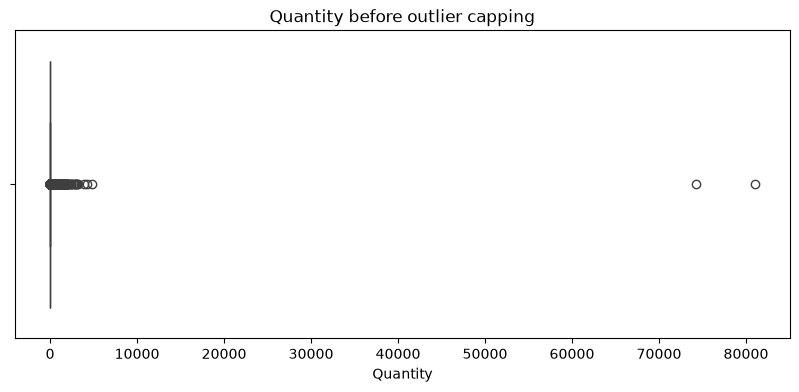

In [21]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df["Quantity"])

plt.title("Quantity before outlier capping")
plt.xlabel("Quantity")

plt.savefig(
    "../report/figures/quantity_before.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


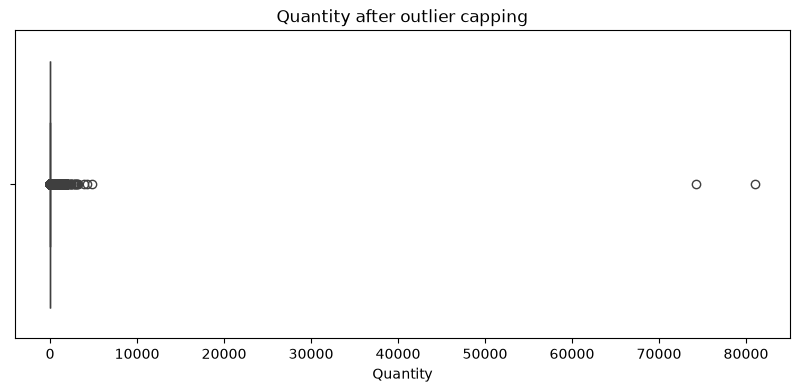

In [23]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df["Quantity"])

plt.title("Quantity after outlier capping")
plt.xlabel("Quantity")

plt.savefig(
    "../report/figures/quantity_after.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

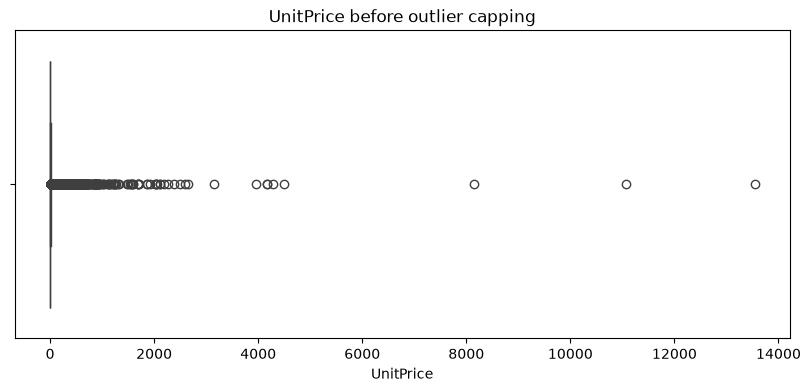

In [24]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df["UnitPrice"])

plt.title("UnitPrice before outlier capping")

plt.savefig(
    "../report/figures/unitprice_before.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

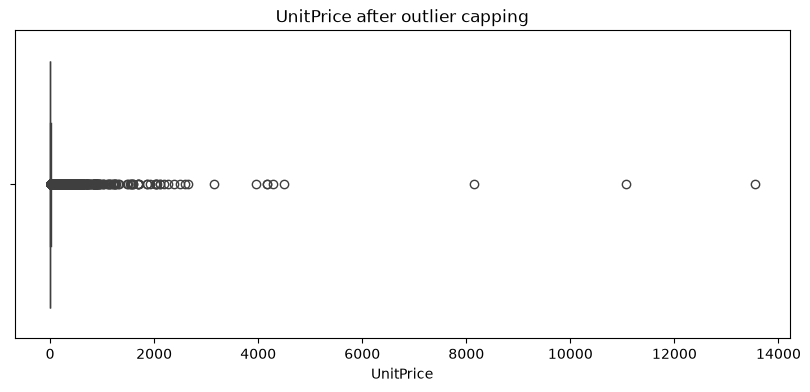

In [25]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df["UnitPrice"])

plt.title("UnitPrice after outlier capping")

plt.savefig(
    "../report/figures/unitprice_after.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()